# Kontrola treningu enkodera (etap A)
Weryfikacja `dl/train_encoder.py`: urządzenie, wagi klas stagingu, przepustowość DataLoadera i kroków treningowych, overfit na jednym batchu oraz smoke test skryptu z wznowieniem.

In [1]:
import sys
sys.path.append("/home/emil/studia/inzynierka")

import shutil
import subprocess
import time

import pandas as pd
import torch

from dl.config import BATCH_SIZE, MODELS_DIR, REPO, STAGES
from dl.dataset import PSGEpochDataset
from dl.encoder import PSGEncoder
from dl.train_encoder import (
    compute_losses,
    make_optimizer,
    make_scaler,
    make_train_loader,
    select_device,
    set_seed,
    stage_class_frequencies,
    stage_class_weights,
    staging_metrics,
    to_device,
    train_step,
)

pd.set_option("display.max_rows", None)
pd.set_option("display.width", None)
set_seed(42)

## 1. Urządzenie

In [2]:
device = select_device()
pd.Series({
    "device": device.type,
    "gpu": torch.cuda.get_device_name(0) if device.type == "cuda" else None,
    "torch": torch.__version__,
    "cpu_threads": torch.get_num_threads(),
})

device                cpu
gpu                  None
torch          2.15.0+cpu
cpu_threads            12
dtype: object

## Wnioski

## 2. Częstości klas stagingu i wagi

In [3]:
train_dataset = PSGEpochDataset("train")
counts, frequencies = stage_class_frequencies(train_dataset)
class_weights = stage_class_weights(frequencies)

In [4]:
stage_weights = pd.DataFrame({
    "count": counts,
    "frequency": frequencies,
    "weight": class_weights.numpy(),
}, index=STAGES)
stage_weights

,count,frequency,weight
W,89355,0.258155,0.915391
N1,51890,0.149915,1.201225
N2,137249,0.396526,0.738604
N3,32904,0.095063,1.508488
REM,34731,0.100341,1.468276


In [5]:
(stage_weights["frequency"] * stage_weights["weight"]).sum()

np.float64(1.0000000167571281)

## Wnioski

## 3. Przepustowość
### DataLoader train
Po 5 batchach rozgrzewki mierzony jest czas pobrania kolejnych 50 batchy.

In [6]:
WARMUP_BATCHES = 5
TIMED_BATCHES = 50
WORKER_OPTIONS = [0, 4, 8]

In [7]:
def loader_throughput(dataset, num_workers):
    iterator = iter(make_train_loader(dataset, num_workers=num_workers))
    for _ in range(WARMUP_BATCHES):
        next(iterator)
    start = time.perf_counter()
    for _ in range(TIMED_BATCHES):
        next(iterator)
    return TIMED_BATCHES / (time.perf_counter() - start)

In [8]:
loader_rates = pd.Series(
    {workers: loader_throughput(train_dataset, workers) for workers in WORKER_OPTIONS},
    name="batches_per_s",
).rename_axis("num_workers")
loader_rates

num_workers
0     3.408982
4    34.149228
8    43.025142
Name: batches_per_s, dtype: float64

### Kroki treningowe
Pełny krok (forward, backward, optymalizator) na stałym batchu, bez udziału DataLoadera.

In [9]:
WARMUP_STEPS = 2
TIMED_STEPS = 10
benchmark_batch = next(iter(make_train_loader(train_dataset, num_workers=0)))

In [10]:
model = PSGEncoder().to(device)
optimizer = make_optimizer(model)
scaler = make_scaler(device)
weights_on_device = class_weights.to(device)
for _ in range(WARMUP_STEPS):
    train_step(model, benchmark_batch, optimizer, None, scaler, weights_on_device, device)
if device.type == "cuda":
    torch.cuda.synchronize()
start = time.perf_counter()
for _ in range(TIMED_STEPS):
    train_step(model, benchmark_batch, optimizer, None, scaler, weights_on_device, device)
if device.type == "cuda":
    torch.cuda.synchronize()
step_rate = TIMED_STEPS / (time.perf_counter() - start)
step_rate

0.41015437207696465

### Szacowany czas przejścia po train
Krok w pętli ograniczony jest wolniejszym z dwóch elementów: DataLoaderem (8 workerów) albo samym krokiem treningowym. Na CPU workery i obliczenia dzielą te same rdzenie, więc wynik jest dolnym oszacowaniem.

In [11]:
steps_per_pass = len(train_dataset) // BATCH_SIZE
effective_rate = min(loader_rates[8], step_rate)
pd.Series({
    "steps_per_pass": steps_per_pass,
    "effective_steps_per_s": effective_rate,
    "pass_minutes": steps_per_pass / effective_rate / 60,
})

steps_per_pass           1423.000000
effective_steps_per_s       0.410154
pass_minutes               57.823757
dtype: float64

## Wnioski

## 4. Overfit na jednym batchu
Model bez channel dropoutu i dropoutu embeddingu, stały LR 1e-3 (bez schedulera), 300 kroków na tym samym batchu.

In [12]:
OVERFIT_STEPS = 300
OVERFIT_LR = 1e-3
set_seed(42)
overfit_batch = next(iter(make_train_loader(train_dataset, num_workers=0)))
overfit_model = PSGEncoder(channel_dropout=0.0, embedding_dropout=0.0).to(device)
overfit_optimizer = make_optimizer(overfit_model, lr=OVERFIT_LR)
overfit_scaler = make_scaler(device)

In [13]:
def batch_staging(model, batch):
    model.eval()
    batch_on_device = to_device(batch, device)
    with torch.no_grad():
        _, logits = model(batch_on_device)
    losses = compute_losses(logits, batch_on_device, weights_on_device)
    metrics, _ = staging_metrics(logits["stage"].float().cpu(), batch["stage"], batch["stage_valid"])
    return {"stage_loss_eval": losses["stage"].item(), "accuracy_eval": metrics["accuracy"], "kappa_eval": metrics["kappa"]}

In [14]:
overfit_start = batch_staging(overfit_model, overfit_batch)
overfit_history = [
    train_step(overfit_model, overfit_batch, overfit_optimizer, None, overfit_scaler, weights_on_device, device)
    for _ in range(OVERFIT_STEPS)
]
overfit_end = batch_staging(overfit_model, overfit_batch)

In [15]:
overfit_history = pd.DataFrame(overfit_history)
overfit_history.iloc[[0, 49, 99, 149, 199, 249, 299]]

,stage,arousal,limb,resp,total
0,1.635342,0.739485,0.663243,0.663411,1.635342
49,0.001537,0.971194,0.582095,0.693696,0.001537
99,0.000205,0.994287,0.588771,0.705305,0.000205
149,0.000136,0.999906,0.589112,0.708111,0.000136
199,0.000100,1.003979,0.589721,0.710363,0.000100
249,0.000078,1.007228,0.590478,0.712197,0.000078
299,0.000062,1.009943,0.591226,0.713777,0.000062


In [16]:
pd.DataFrame({"start": overfit_start, "end": overfit_end})

,start,end
stage_loss_eval,1.602889,0.000063
accuracy_eval,0.219008,1.000000
kappa_eval,0.000044,1.000000


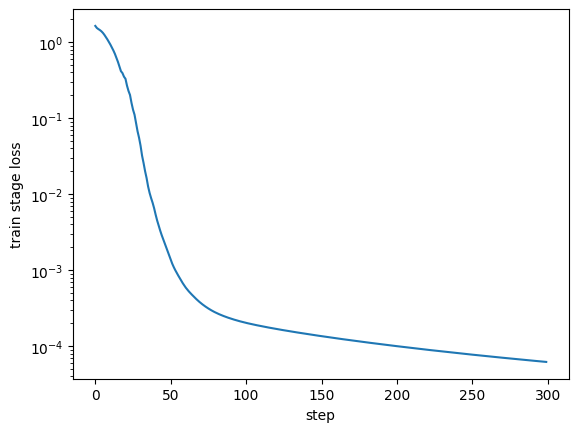

In [17]:
overfit_history["stage"].plot(logy=True, xlabel="step", ylabel="train stage loss");

## Wnioski

## 5. Smoke test skryptu
Pierwsze uruchomienie: `--max-steps 20 --val-batches 5`. Wznowienie: `--resume --max-steps 40 --val-batches 5`. `--max-steps` jest globalnym limitem kroków, więc przy wznowieniu limit podniesiono do 40, żeby było co trenować.

In [18]:
RUN_NAME = "smoke_test"
run_dir = MODELS_DIR / RUN_NAME
shutil.rmtree(run_dir, ignore_errors=True)

In [19]:
def run_script(*arguments):
    result = subprocess.run(
        [sys.executable, "-m", "dl.train_encoder", "--run-name", RUN_NAME, "--val-batches", "5", *arguments],
        cwd=REPO, capture_output=True, text=True,
    )
    print(result.stdout)
    print(result.stderr[-2000:])
    return result.returncode

In [20]:
run_script("--max-steps", "20")

device cpu, steps per pass 1423, eval every 355, total steps 20
step 20 pass 0.01 train 1.5913 val 1.5726 kappa -0.0137 patience 0
finished at step 20, best kappa -0.0137




0

In [21]:
first_run = {
    "files": sorted(path.name for path in run_dir.iterdir()),
    "last_step": torch.load(run_dir / "last.pt", weights_only=False)["step"],
    "best_step": torch.load(run_dir / "best.pt", weights_only=False)["step"],
}
first_run

{'files': ['best.pt', 'confusion_best.csv', 'last.pt', 'log.csv'],
 'last_step': 20,
 'best_step': 20}

In [22]:
run_script("--resume", "--max-steps", "40")

resumed from step 20, best kappa -0.0137, patience 0
device cpu, steps per pass 1423, eval every 355, total steps 40
step 40 pass 0.03 train 1.5509 val 1.5158 kappa 0.1095 patience 0
finished at step 40, best kappa 0.1095




0

In [23]:
last = torch.load(run_dir / "last.pt", weights_only=False)
best = torch.load(run_dir / "best.pt", weights_only=False)
pd.Series({
    "files": sorted(path.name for path in run_dir.iterdir()),
    "last_step": last["step"],
    "last_patience": last["patience_counter"],
    "scheduler_last_epoch": last["scheduler"]["last_epoch"],
    "best_step": best["step"],
    "best_kappa": best["kappa"],
    "config_keys": len(best["config"]),
})

files                   [best.pt, confusion_best.csv, last.pt, log.csv]
last_step                                                            40
last_patience                                                         0
scheduler_last_epoch                                                 40
best_step                                                            40
best_kappa                                                     0.109459
config_keys                                                          59
dtype: object

In [24]:
smoke_log = pd.read_csv(run_dir / "log.csv")
smoke_log.T

,0,1
step,20.000000,40.000000
pass,0.014055,0.028110
lr,0.000040,0.000040
train_stage,1.591324,1.550937
train_arousal,0.758010,0.767260
train_limb,0.649269,0.649867
train_resp,0.662450,0.662064
train_total,1.591324,1.550937
val_stage,1.572561,1.515779
val_arousal,0.667409,0.709644


In [25]:
smoke_log.isna().sum().sum()

np.int64(0)

In [26]:
pd.read_csv(run_dir / "confusion_best.csv", index_col=0)

,W,N1,N2,N3,REM
true,,,,,
W,213,0,439,0,0
N1,52,0,426,0,0
N2,112,0,927,0,0
N3,51,0,42,0,0
REM,12,0,239,0,0


## Wnioski

## 6. Zgodność metryk z sklearn.metrics
Predykcje modelu z `models/smoke_test/best.pt` na 5 batchach val. Metryki z `train_encoder.py` porównano z `cohen_kappa_score`, `accuracy_score`, `f1_score(average=None)` i `confusion_matrix` z sklearn.

In [3]:
import numpy as np
from sklearn import metrics as skm

from dl.train_encoder import collect_predictions, make_val_loader

COMPARE_BATCHES = 5
checkpoint = torch.load(MODELS_DIR / "smoke_test" / "best.pt", weights_only=False)
compare_model = PSGEncoder().to(device)
compare_model.load_state_dict(checkpoint["model"])
val_loader = make_val_loader(PSGEpochDataset("val"))

In [4]:
logits, targets = collect_predictions(compare_model, val_loader, device, COMPARE_BATCHES)
valid = targets["stage_valid"] > 0
y_true = targets["stage"][valid].numpy()
y_pred = logits["stage"][valid].argmax(dim=1).numpy()
len(y_true)

2513

In [5]:
own_metrics, own_confusion = staging_metrics(logits["stage"], targets["stage"], targets["stage_valid"])
labels = list(range(len(STAGES)))
sklearn_metrics = {
    "kappa": skm.cohen_kappa_score(y_true, y_pred, labels=labels),
    "accuracy": skm.accuracy_score(y_true, y_pred),
    **{f"f1_{name}": value for name, value in zip(STAGES, skm.f1_score(y_true, y_pred, labels=labels, average=None, zero_division=0))},
}
sklearn_confusion = skm.confusion_matrix(y_true, y_pred, labels=labels)

In [6]:
metric_comparison = pd.DataFrame({
    "train_encoder": {name: own_metrics[name] for name in sklearn_metrics},
    "sklearn": sklearn_metrics,
})
metric_comparison["abs_diff"] = (metric_comparison["train_encoder"] - metric_comparison["sklearn"]).abs()
metric_comparison

,train_encoder,sklearn,abs_diff
kappa,0.109459,0.109459,4.163336e-17
accuracy,0.453641,0.453641,0.000000e+00
f1_W,0.390110,0.390110,0.000000e+00
f1_N1,0.000000,0.000000,0.000000e+00
f1_N2,0.595758,0.595758,0.000000e+00
f1_N3,0.000000,0.000000,0.000000e+00
f1_REM,0.000000,0.000000,0.000000e+00


In [7]:
pd.DataFrame(own_confusion, index=STAGES, columns=STAGES).rename_axis("true")

,W,N1,N2,N3,REM
true,,,,,
W,213,0,439,0,0
N1,52,0,426,0,0
N2,112,0,927,0,0
N3,51,0,42,0,0
REM,12,0,239,0,0


In [8]:
pd.DataFrame(sklearn_confusion, index=STAGES, columns=STAGES).rename_axis("true")

,W,N1,N2,N3,REM
true,,,,,
W,213,0,439,0,0
N1,52,0,426,0,0
N2,112,0,927,0,0
N3,51,0,42,0,0
REM,12,0,239,0,0


In [9]:
pd.Series({
    "max_abs_diff_metrics": metric_comparison["abs_diff"].max(),
    "max_abs_diff_confusion": int(np.abs(own_confusion - sklearn_confusion).max()),
})

max_abs_diff_metrics      4.163336e-17
max_abs_diff_confusion    0.000000e+00
dtype: float64

## Wnioski